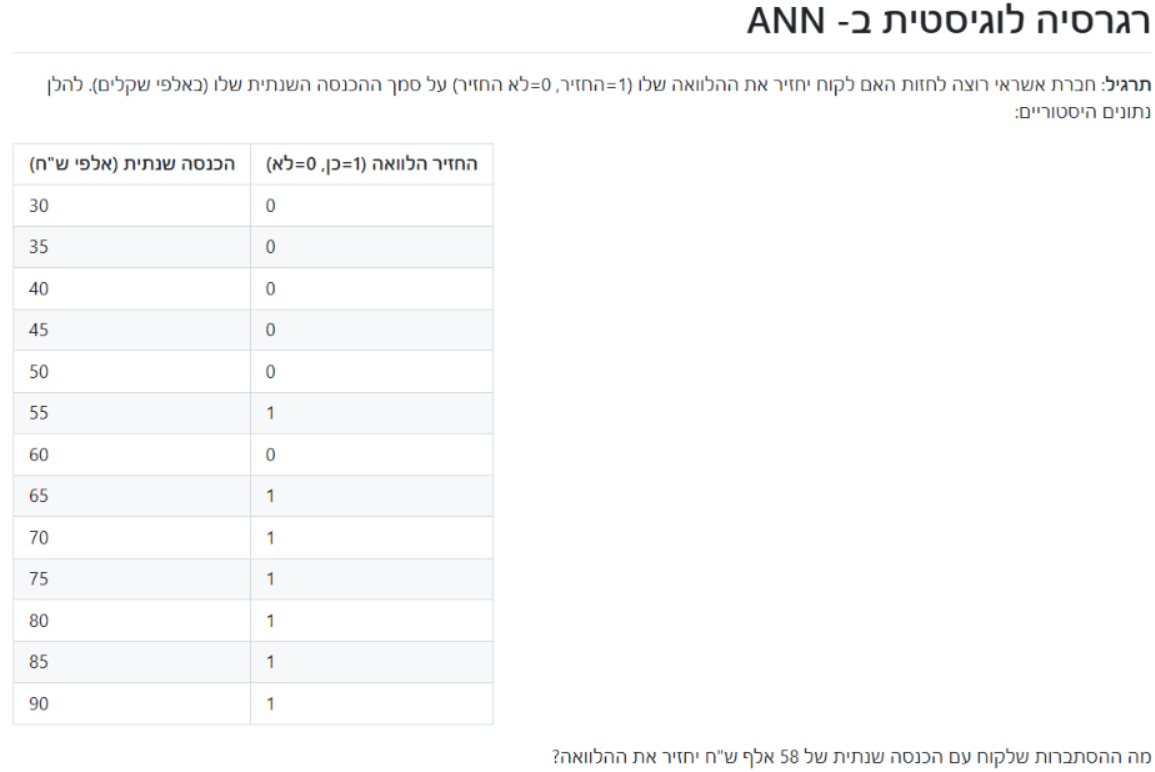

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Dense, Input  
import time 

script_start = time.time()

# ----- data -----
X = np.array([30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90], dtype=float)\
       .reshape(-1, 1)
y = np.array([0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1], dtype=float).reshape(-1, 1)

# scale input
scaler = StandardScaler()
X_s = scaler.fit_transform(X)

# ----- ANN: single neuron sigmoid -----
model = Sequential([
    Input(shape=(1,)),                   # Explicitly define input shape first
    Dense(1, activation='sigmoid')       # Your single output neuron with Sigmoid
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# train
training_start = time.time()
model.fit(X_s, y, epochs=500, verbose=0)

training_end = time.time()

print(f"⏱️ Actual model training took: {training_end - training_start:.2f} seconds")

# ----- predictions -----
probs = model.predict(X_s, verbose=1)
preds = (probs > 0.5).astype(int)

print("X: ", [30, 35, 40, 45, 50, 55, 60, 65, 70, 75])
print("Predicted probabilities:", np.round(probs.ravel(), 3))
print("Predicted classes:", preds.ravel())

print()
print('prediction for 58K:')
print(model.predict(scaler.transform([[58]])))

⏱️ Actual model training took: 31.01 seconds
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
X:  [30, 35, 40, 45, 50, 55, 60, 65, 70, 75]
Predicted probabilities: [0.108 0.152 0.209 0.28  0.364 0.458 0.555 0.647 0.73  0.8   0.855 0.897
 0.928]
Predicted classes: [0 0 0 0 0 0 1 1 1 1 1 1 1]

prediction for 58K:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
[[0.5160675]]


In [2]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs available: {len(gpus)}")

GPUs available: 0
